# hitrostni profil

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import scipy as sc
from matplotlib.colors import LogNorm
from timeit import default_timer as timer

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})
np.set_printoptions(linewidth=np.inf) #print in one row

In [26]:
def jacobi(A,q,RP,N=1, hiska=True):
    D = np.diag(A)
    # D_matrix = np.diagflat(D)
    # B = np.linalg.inv(D_matrix)
    # R = A - D_matrix
    u = np.zeros_like(q)

    #iteracije
    for n in range(N):
        u_n = np.zeros_like(u)
        _, u_n = RP(np.zeros((Nx*Ny,Nx*Ny)), u_n, Nx)

        for j in range(1,Ny-1):
            for i in range(1,Nx-1):
                if (hiska and ((i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1) or (j*dy > H/3 and j*dy < 2*H/3) or (j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3))))) or hiska==False: #le notranje točke hišice! TODO strehica
                    ij_index = j*Nx + i
                    u_n[ij_index] = (q[ij_index] + 1/dx**2*(u[ij_index+1] + u[ij_index-1]) +
                                                1/dy**2*(u[ij_index+Nx] + u[ij_index-Nx])) / D[ij_index]
        #u_n = np.dot(B, q-R@u) #matrično, hitreje za male Nx,Ny
        u = u_n
    return u
def gauss_seidel(A,q,RP,N=1,hiska=True):
    D = np.diag(A)
    u = np.zeros_like(q)

    #iteracije
    for n in range(N):
        u_n = np.zeros_like(u)
        _,u_n = RP(np.zeros((Nx*Ny,Nx*Ny)), u_n, Nx)
        
        for j in range(1,Ny-1):
            for i in range(1,Nx-1):
                if (hiska and ((i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1) or (j*dy > H/3 and j*dy < 2*H/3) or (j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3))))) or hiska==False: #le notranje točke hišice! TODO strehica
                    ij_index = j*Nx + i
                    u_n[ij_index] = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
                                                                + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
        u = u_n
    return u
def SOR(A,q,omega,RP,N,Nx, u_init=None, hiska=True):
    if u_init == None:
        u = np.zeros_like(q)
    elif u_init == int or type(u_init) == float:
        u = np.full(q.shape,u_init)
    elif u_init == np.ndarray:
        u = u_init
    
    #u_1 = jacobi(A,q,RP,N)
    #u_1 = gauss_seidel(A,q,RP,N)
    Ny=Nx
    dx=dy=1./(Nx-1)

    #iteracije
    for n in range(N):
        u_n = np.zeros_like(u)
        _, u_n = RP(np.zeros((Nx*Ny,Nx*Ny)), u_n, Nx)
            
        for j in range(1,Ny-1):
            for i in range(1,Nx-1):
                if (hiska and ((i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1) or (j*dy > H/3 and j*dy < 2*H/3) or (j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3))))) or hiska==False: #le notranje točke hišice! TODO strehica
                    ij_index = j*Nx + i
                    u_gs= 1/A[ij_index,ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
                                                                + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
                    u_n[ij_index] = u[ij_index] + omega*(u_gs - u[ij_index])
        u = u_n
    return u
def SOR_č(A,q,RP,N, Nx, u_init=None, hiska=True):
    '''Čebišev pospešek'''
    if u_init == None:
        u = np.zeros_like(q)
    elif u_init == int or type(u_init) == float:
        u = np.full(q.shape,u_init)
    elif u_init == np.ndarray:
        u = u_init

    Ny=Nx
    dx=dy=1./(Nx-1)

    omega = 1
    rho_j = 1/(1/dx**2+1/dy**2) * (1/dx**2*np.cos(np.pi/Nx) + 1/dy**2*np.cos(np.pi/Ny)) #spektralni radij
    omega_1 = 1/ (1-0.5*rho_j**2)

    #iteracije
    for n in range(N):
        u_n = np.zeros_like(u)
        _, u_n = RP(np.zeros((Nx*Ny,Nx*Ny)), u_n, Nx)
            
        for j in range(1,Ny-1):
            for i in range(1,Nx-1):
                if (hiska and ((i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1) or (j*dy > H/3 and j*dy < 2*H/3) or (j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3))))) or hiska==False:
                    if i%2==(j)%2: #liha mesta
                        ij_index = j*Nx + i
                        u_gs= 1/A[ij_index,ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
                                                                    + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
                        u_n[ij_index] = u[ij_index] + omega_1*(u_gs - u[ij_index])
                    elif i%2==(j+1)%2: #soda mesta
                        ij_index = j*Nx + i
                        u_gs= 1/A[ij_index,ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u_n[ij_index-1]) 
                                                                    + 1/dy**2*(u[ij_index+Nx] + u_n[ij_index-Nx]))
                        u_n[ij_index] = u[ij_index] + omega*(u_gs - u[ij_index])
        
        omega = 1/ (1-0.25*rho_j**2*omega)
        omega_1 = 1/ (1-0.25*rho_j**2*omega_1)
        u = u_n
    return u

### pravokotna cev

In [177]:
dp = 1 #tlačni graident v z smeri
L=1 #širina cevi - x
H=1 #višina cevi - y
Nx = 50 #željeno
k = round(np.log2(Nx-1)) #za romberg integracijo
Nx=1 + 2**k #št. točk = št. delitev +1!
Ny=1 + 2**k
dx=L/(Nx-1)
dy=H/(Ny-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
Nx,Ny,dx,dy,k

št. računskih točk: 4225


(65, 65, 0.015625, 0.015625, 6)

In [178]:
# DE, RP
A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
b = np.zeros(((Nx)*Ny))

# DE
for j in range(1,Ny-1):
    for i in range(1,Nx-1):
        ij_index = j*(Nx) + i #- Nx-1
        ij = 2*(1/dx**2 + 1/dy**2)
        ij_dx = -1/dx**2
        ij_dy = -1/dy**2

        #center
        A[ij_index, ij_index] += ij
        # okolica
        A[ij_index, ij_index-1] += ij_dx #levo
        A[ij_index, ij_index+1] += ij_dx #desno
        A[ij_index, ij_index-Nx] += ij_dy #dol
        A[ij_index, ij_index+Nx] += ij_dy #gor
        
        b[ij_index] = dp #tlačni gradient, viskoznost=1

def RP(A,b,Nx):
    # RP Dirichlet
    v_rp=0
    Ny=Nx
    for i in range(Nx):
        #spodaj
        A[i, i] = 1
        b[i] = v_rp
        #zgoraj
        A[-Nx+i, -Nx+i] = 1
        b[-Nx+i] = v_rp
    for j in range(Ny):
        #levo
        A[j*Nx, j*Nx] = 1
        b[j*Nx] = v_rp
        #desno
        A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
        b[j*Nx+Nx-1] = v_rp
    return A,b
A,b = RP(A,b,Nx)

In [179]:
# LU razcep z delnim pivotiranjem
v_lu = np.linalg.solve(A,b)#.reshape((Nx,Ny))

In [180]:
# Cholesky - SYM matrika A! čudno!
# v_c = sc.linalg.cho_solve((A,False),b)
# res_cho = np.sum(np.abs(v_c-v_lu))
# res_cho

In [181]:
N=100
v_j = jacobi(A,b, RP, N=N, hiska=False)#.reshape((Nx,Ny))
res_jac = np.sum(np.abs(v_j-v_lu))
res_jac

124.34705299088287

In [182]:
v_g = gauss_seidel(A,b,RP,N=N,hiska=False)#.reshape((Nx,Ny))
v_g_kvadrat = np.copy(v_g)
res_gauss = np.sum(np.abs(v_g-v_lu))
res_gauss

108.96983313732059

In [183]:
omega = 2/(1+np.pi/Nx) #ocena
v_sor = SOR(A,b, omega , RP, N, Nx, hiska=False)
res_sor = np.sum(np.abs(v_sor-v_lu))
res_sor, res_gauss-res_sor

(0.10936283531580615, 108.86047030200479)

In [184]:
v_sorč = SOR_č(A,b, RP, N,Nx,hiska=False)
res_sorč = np.sum(np.abs(v_sorč-v_lu))
res_sorč, res_sor-res_sorč

(0.21878180490456633, -0.10941896958876018)

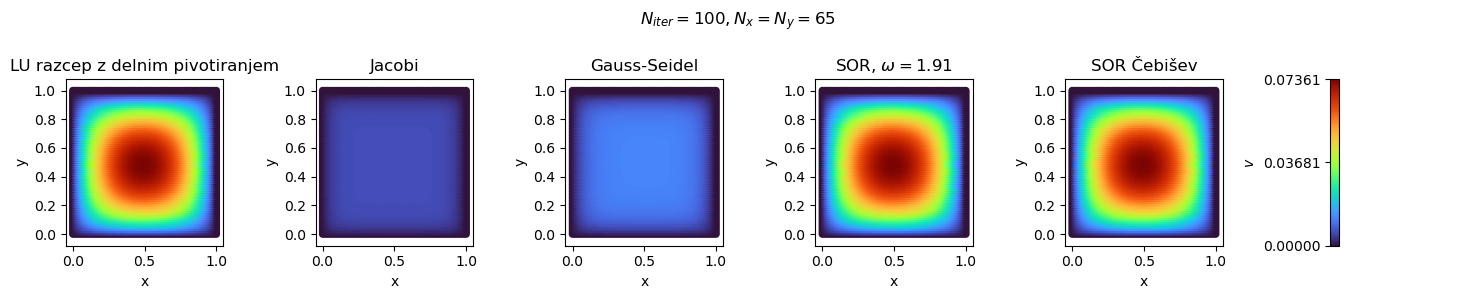

In [185]:
cmap = plt.get_cmap('turbo')
point_size = 30

fig, ax = plt.subplots(1, 6, figsize=(15, 3))
plt.suptitle(f'$N_{{iter}}={N}, N_x=N_y={Nx}$')

vmin = min(v_j.min(), v_g.min(), v_sor.min())
vmax = max(v_j.max(), v_g.max(), v_sor.max())

sc1 = ax[ 0].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_lu, cmap=cmap)
ax[0].axis('equal')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0,].set_title('LU razcep z delnim pivotiranjem')

sc2 = ax[1].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_j, cmap=cmap, vmin=vmin, vmax=vmax)
ax[1].axis('equal')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].set_title(f'Jacobi')

sc3 = ax[2].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_g, cmap=cmap, vmin=vmin, vmax=vmax)
ax[2].axis('equal')
ax[2].set_xlabel('x')
ax[2].set_ylabel('y')
ax[2].set_title(f'Gauss-Seidel')

sc4 = ax[3].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_sor, cmap=cmap, vmin=vmin, vmax=vmax)
ax[3].axis('equal')
ax[3].set_xlabel('x')
ax[3].set_ylabel('y')
ax[3].set_title(f'SOR, $\omega=${omega:.2f}')

sc4 = ax[4].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_sorč, cmap=cmap, vmin=vmin, vmax=vmax)
ax[4].axis('equal')
ax[4].set_xlabel('x')
ax[4].set_ylabel('y')
ax[4].set_title(f'SOR Čebišev')

ax[5].cla()
ax[5].axis('off')

cbar = plt.colorbar(sc1, ax=ax[5], label='$v$', location='left')
cbar.set_ticks([vmin, (vmin + vmax) / 2, vmax])
plt.tight_layout()
# plt.savefig(f'./slike/kvadrat_Nx{Nx}.pdf')

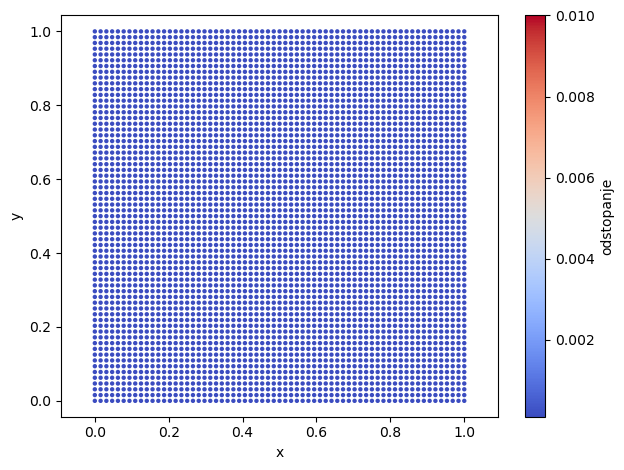

In [186]:
T_1 = v_sor
T_2 = v_lu
point_size = 10
cmap = plt.get_cmap('coolwarm')

vmim = min(min(np.abs(T_1 - T_2)), min(np.abs(T_1 - T_2)))
vmax = max(max(np.abs(T_1 - T_2)), max(np.abs(T_1 - T_2)))
vmin = max(vmim, 1e-2)#log scale
norm = LogNorm(vmin=vmin, vmax=vmax)

tt=plt.scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=T_1-T_2, cmap=cmap, vmin=vmin, vmax=vmax)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(tt, label='odstopanje')
plt.tight_layout()

In [187]:
def C(hitr,hiska=True,dx=1):
    #poiseuillov koef.
    #hitr = hitr.reshape(Nx,Ny) #2D!!!"
    dy=dx
    if hiska: pretok = sc.integrate.simps(sc.integrate.simps(hitr,axis=1,dx=dy), axis=0,dx=dx)
    else: pretok = sc.integrate.romb(sc.integrate.romb(hitr,axis=1,dx=dy), axis=0,dx=dx)
    eta=1#brezdim
    dp=1 #desna stran DE
    if hiska: S = H*L*(5/9)
    else: S=H*L #površina
    return pretok * 8*np.pi*eta / (S**2*dp)
C(v_j.reshape((Nx,Ny)),hiska=False,dx=dx), C(v_g.reshape((Nx,Ny)),hiska=False,dx=dx), C(v_sor.reshape((Nx,Ny)),hiska=False,dx=dx), C(v_sorč.reshape((Nx,Ny)),hiska=False,dx=dx)

(0.11975107014053606,
 0.21416313075993162,
 0.8824101176437945,
 0.8817376879651965)

In [188]:
N_list = [9, 17,33, 65]
C_j = [0.7604511820458152, 0.7604511820458152, 0.3633632467730551, 0.11975107014053606]
C_g = [0.8627230166015863 ,0.8627230166015863, 0.5629150793769304, 0.21416313075993162]
C_sor = [0.8802604739738354, 0.8802604739738354, 0.8825141642707514, 0.8824101176437945]
C_čeb = [0.8802604739738353, 0.8802604739738353, 0.882514200883252, 0.8817376879651965]

Text(0.5, 1.0, '$N_{iter}=100$')

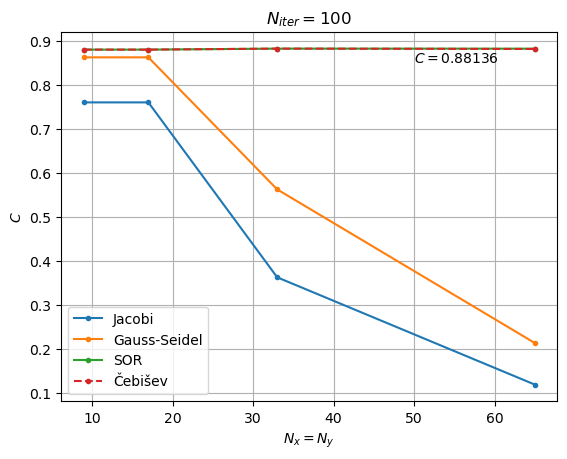

In [189]:
plt.plot(N_list, C_j, '.-',label='Jacobi')
plt.plot(N_list, C_g, '.-',label='Gauss-Seidel')
plt.plot(N_list, C_sor, '.-',label='SOR')
plt.plot(N_list, C_čeb, '.--',label='Čebišev')
plt.text(50, np.average(C_sor)-0.03, f'$C=${np.average(C_sor):.5f}')
plt.legend()
plt.grid()
plt.xlabel('$N_x=N_y$')
plt.ylabel('$C$')
plt.title(f'$N_{{iter}}={N}$')
# plt.savefig('./slike/100iter_kvadrat_C.pdf')

## podana cev - hiška

In [20]:
scale = 30
dp = 1 #tlačni graident v z smeri
L=1 #širina cevi - x
H=1 #višina cevi - y
Nx=1 + 3*scale #št. točk = št. delitev +1!
Ny=1 + 3*scale #večkratniki št. 3, zaradi delitve na tretjine
dy=H/(Ny-1)
print('št. računskih točk:',(Nx)*(Ny))

#diskretizacija
pointsall=np.zeros(((Nx)*(Ny),2))
for j in range(Ny):
    for i in range(Nx):
        index = (j)*(Nx)+i
        pointsall[index] = [i*dx, j*dy]
Nx,Ny,dx,dy

št. računskih točk: 8281


(91, 91, 0.043478260869565216, 0.011111111111111112)

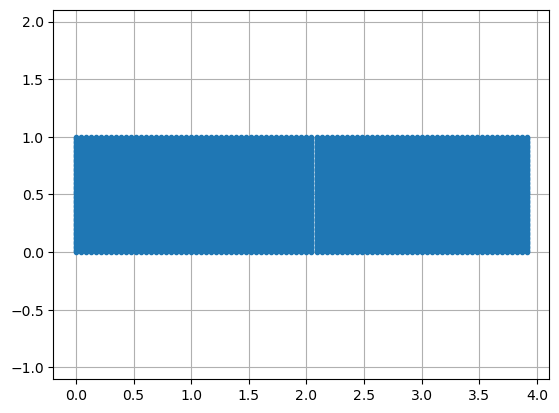

In [21]:
plt.plot(pointsall[:,0], pointsall[:,1],'.')
plt.axis('equal')
plt.grid()

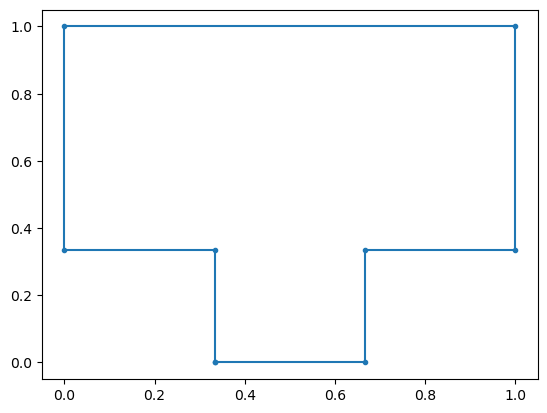

In [22]:
x_ = [L/3,  L/3,    0,      0,  L,  L,      2*L/3,  2*L/3,  L/3]
y_ = [0,    H/3,    H/3,    H,  H,  H/3,    H/3,    0,      0]
plt.plot(x_,y_,'.-')

In [23]:
# DE, RP
A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
b = np.zeros(((Nx)*Ny))

# DE
for j in range(1,Ny-1):
    for i in range(1,Nx-1):
        if i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1:
            # plt.plot(i*dx,j*dy,'ro')
            ij_index = j*(Nx) + i
            #print(i,j, ij_index)
            ij = 2*(1/dx**2 + 1/dy**2)
            ij_dx = -1/dx**2
            ij_dy = -1/dy**2
            #center
            A[ij_index, ij_index] += ij
            # okolica
            A[ij_index, ij_index-1] += ij_dx #levo
            A[ij_index, ij_index+1] += ij_dx #desno
            A[ij_index, ij_index-Nx] += ij_dy #dol
            A[ij_index, ij_index+Nx] += ij_dy #gor
            b[ij_index] = dp #tlačni gradient, viskoznost=1
        elif j*dy > H/3 and j*dy < 2*H/3:
            # plt.plot(i*dx,j*dy,'ro')
            ij_index = j*(Nx) + i
            ij = 2*(1/dx**2 + 1/dy**2)
            ij_dx = -1/dx**2
            ij_dy = -1/dy**2
            #center
            A[ij_index, ij_index] += ij
            # okolica
            A[ij_index, ij_index-1] += ij_dx #levo
            A[ij_index, ij_index+1] += ij_dx #desno
            A[ij_index, ij_index-Nx] += ij_dy #dol
            A[ij_index, ij_index+Nx] += ij_dy #gor
            b[ij_index] = dp #tlačni gradient, viskoznost=1
        elif j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3)):
            # plt.plot(i*dx,j*dy,'bo')
            ij_index = j*(Nx) + i

            ij = 2*(1/dx**2 + 1/dy**2)
            ij_dx = -1/dx**2
            ij_dy = -1/dy**2
            #center
            A[ij_index, ij_index] += ij
            # okolica
            A[ij_index, ij_index-1] += ij_dx #levo
            A[ij_index, ij_index+1] += ij_dx #desno
            A[ij_index, ij_index-Nx] += ij_dy #dol
            A[ij_index, ij_index+Nx] += ij_dy #gor
            b[ij_index] = dp #tlačni gradient, viskoznost=1
        else: #izpust
            # plt.plot(i*dx,j*dy,'ko')
            ij_index = j*(Nx) + i
            #print(ij_index)
            A[ij_index, ij_index] = 1
            b[ij_index] = 0 #tlačni gradient, viskoznost=1
def RP1(A,b,Nx):
    # RP Dirichlet
    v_rp=0
    Ny=Nx
    dx=dy=1./(Nx-1)
    for i in range(Nx):
        #spodaj rob - izogib singularnosti
        # plt.plot(i*dx,0,'bo')
        A[i, i] = 1
        b[i] = 0 #tlačni gradient, viskoznost=1
        #spodaj
        if i*dx >= L/3 and i*dx <= 2*L/3: #sredina
            # plt.plot(i*dx,0,'go')
            A[i, i] = 1
            b[i] = v_rp
        if i>0 and i<Nx and (i*dx <= L/3 or i*dx >= 2*L/3): #zamik na robovih za 1/3 gor
            # plt.plot(i*dx,(H/3),'go')
            A[i+int((H/3)/dy)*Nx, i+int((H/3)/dy)*Nx] = 1
            b[i+int((H/3)/dy)*Nx] = v_rp
        #zgoraj: TODO strehica
        # plt.plot(i*dx,H,'go')
        A[-Nx+i, -Nx+i] = 1
        b[-Nx+i] = v_rp
    for j in range(Ny):
        #levod-deso rob - izogib singularnosti
        # plt.plot(0,j*dy,'bo')
        # plt.plot(L,j*dy,'bo')
        A[j*Nx, j*Nx] = 1
        b[i] = 0 #tlačni gradient, viskoznost=1
        A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
        b[j*Nx+Nx-1] = v_rp
        if j*dy >= H/3 and j*dy <= 2*H/3: #sredina
            #levo
            # plt.plot(0,j*dy,'go')
            A[j*Nx, j*Nx] = 1
            b[j*Nx] = v_rp
            #desno
            # plt.plot(L,j*dy,'go')
            A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
            b[j*Nx+Nx-1] = v_rp
        elif j*dy < H/3 and j>0: #spodnja 1/3
            #levo
            # plt.plot(H/3,j*dy,'go')
            A[j*Nx, j*Nx+int((H/3)/dx)] = 1
            b[j*Nx] = v_rp
            #desno
            # plt.t(i*dx,H,'go')
            A[j*Nx+Nx-1, j*Nx-1-int((H/3)/dx)+Nx] = 1
            b[j*Nx+Nx-1] = v_rp
        elif j>0 and j<Ny-1: # j*dy < H/3 #TODO strehica zgornja 1/3 -> OK, ker je že povsod vrednost nič (nezdrsni RP)
            #levo
            # plt.plot(0,j*dy,'go')
            A[j*Nx, j*Nx] = 1
            b[j*Nx] = v_rp
            #desno
            # plt.plot(L,j*dy,'go')
            A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
            b[j*Nx+Nx-1] = v_rp
        # elif j==0: #TODO tudi zgornja površina -> else
        #     A[j*Nx, j*Nx] = 1
        #     b[j*Nx] = 0
        #     A[j*Nx+Nx-1, j*Nx+Nx-1] = 1
        #     b[j*Nx+Nx-1] = 0
    return A,b
A,b = RP1(A,b,Nx)

In [206]:
# LU razcep z delnim pivotiranjem - singularnost !!!
v_lu = np.linalg.solve(A,b)#.reshape((Nx,Ny))

In [207]:
Nj=889
v_j = jacobi(A,b, RP1, N=Nj)#.reshape((Nx,Ny)) #pri matričnih operacijah singularno
res_jac = np.sum(np.abs(v_j-v_lu))
res_jac

14.75091566579119

In [208]:
Ng=445
v_g = gauss_seidel(A,b, RP1, N=Ng)
res_gauss = np.sum(np.abs(v_g-v_lu))
res_gauss

14.745648277652103

In [209]:
Ns=28
omega = 2/(1+np.pi/Nx) #ocena
v_sor = SOR(A,b, omega, RP1, Ns, Nx) #.reshape((Nx,Ny))
res_sor = np.sum(np.abs(v_sor-v_lu))
res_sor

6.546455365265798

In [210]:
Nč=31
v_sorč = SOR_č(A,b, RP1, Nč, Nx)
res_sorč = np.sum(np.abs(v_sorč-v_lu))
res_sorč

9.697235819278909

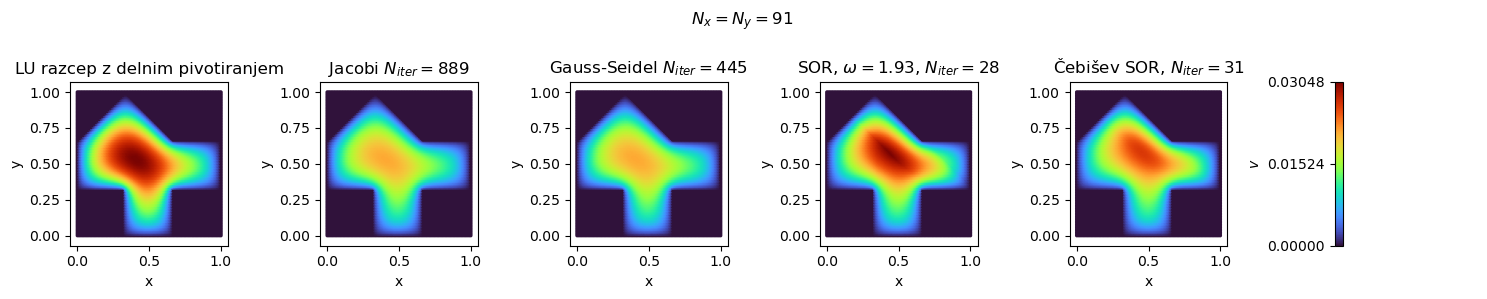

In [211]:
cmap = plt.get_cmap('turbo')
point_size = 7

fig, ax = plt.subplots(1, 6, figsize=(15, 3))
plt.suptitle(f'$N_x=N_y={Nx}$')

vmin = min(v_j.min(), v_g.min(), v_sor.min())
vmax = max(v_j.max(), v_g.max(), v_sor.max())

sc1 = ax[ 0].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_lu, cmap=cmap)
ax[0].axis('equal')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0,].set_title('LU razcep z delnim pivotiranjem')

sc2 = ax[1].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_j, cmap=cmap, vmin=vmin, vmax=vmax)
ax[1].axis('equal')
ax[1].set_xlabel('x')
ax[1].set_ylabel('y')
ax[1].set_title(f'Jacobi $N_{{iter}}={Nj}$')

sc3 = ax[2].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_g, cmap=cmap, vmin=vmin, vmax=vmax)
ax[2].axis('equal')
ax[2].set_xlabel('x')
ax[2].set_ylabel('y')
ax[2].set_title(f'Gauss-Seidel $N_{{iter}}={Ng}$')

sc4 = ax[3].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_sor, cmap=cmap, vmin=vmin, vmax=vmax)
ax[3].axis('equal')
ax[3].set_xlabel('x')
ax[3].set_ylabel('y')
ax[3].set_title(f'SOR, $\omega=${omega:.2f}, $N_{{iter}}={Ns}$')

sc5 = ax[4].scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_sorč, cmap=cmap, vmin=vmin, vmax=vmax)
ax[4].axis('equal')
ax[4].set_xlabel('x')
ax[4].set_ylabel('y')
ax[4].set_title(f'Čebišev SOR, $N_{{iter}}={Nč}$')

ax[5].cla()
ax[5].axis('off')

cbar = plt.colorbar(sc5, ax=ax[5], label='$v$', location='left')
cbar.set_ticks([vmin, (vmin + vmax) / 2, vmax])
plt.tight_layout()
#plt.savefig(f'./slike/cev_nal_Nx{Nx}.pdf')

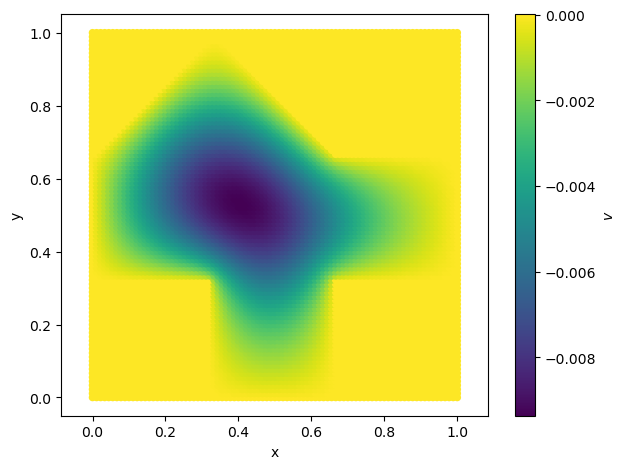

In [212]:
point_size = 30
cmap = plt.get_cmap('viridis')
tt=plt.scatter(pointsall[:, 0], pointsall[:, 1], s=point_size, linewidths=0, c=v_g-v_lu, cmap=cmap)
plt.axis('equal')
plt.xlabel('x')
plt.ylabel('y')
plt.colorbar(tt, label='$v$')
plt.tight_layout()

In [213]:
C(v_sor.reshape((Nx,Ny)),dx=dx)

0.5739166387755265

In [ ]:
def SOR_i(D,q,omega,u):
    Nx=Ny=int(len(q)**0.5)
    dx=dy=1./(Nx-1)

    # Dirichlet RP
    for i in range(Nx): #gor
        u[-Nx+i] = q[-Nx+i]
    for j in range(Ny//2): #desno dol
        u[j*Nx+Nx-1] = q[j*Nx+Nx-1]
    for j in range(Ny//2,Ny-1): #desno gor
        u[j*Nx+Nx-1] = q[j*Nx+Nx-1]
    # Neumann RP
    for i in range(Nx): #spodaj
        u[i] = q[i]*dy + u[i+Nx]
    for j in range(1,Ny): #levo
        u[j*Nx] = q[j*Nx]*dx + u[j*Nx+1]

    for j in range(1,Ny-1):
        for i in range(1,Nx-1):
            ij_index = j*Nx + i
            #u_gs = GS_i(A,q,u)
            u_gs = 1/D[ij_index] * (q[ij_index] + 1/dx**2*(u[ij_index+1] + u[ij_index-1]) 
                                                + 1/dy**2*(u[ij_index+Nx] + u[ij_index-Nx]))
            u[ij_index] = u[ij_index] + omega*(u_gs - u[ij_index])
    return u

In [24]:
def SOR_i(A, q, omega, u_n):
    Nx=Ny=int(len(q)**0.5)
    dx=dy=1./(Nx-1)

    #iteracija
    # _, u_n = RP1(np.zeros((Nx*Ny,Nx*Ny)), u_n, Nx)
    for j in range(1,Ny-1):
        for i in range(1,Nx-1):
            if (i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1) or (j*dy > H/3 and j*dy < 2*H/3) or (j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3))): #le notranje točke hišice
                ij_index = j*Nx + i
                u_gs= 1/A[ij_index,ij_index] * (q[ij_index] + 1/dx**2*(u_n[ij_index+1] + u_n[ij_index-1]) 
                                                            + 1/dy**2*(u_n[ij_index+Nx] + u_n[ij_index-Nx]))
                u_n[ij_index] = u_n[ij_index] + omega*(u_gs - u_n[ij_index])
    return u_n
def DE(Nx):
    Ny=Nx
    dx=dy=1./(Nx-1)
    H=L=1.
    dp=1

    # DE, RP
    A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
    b = np.zeros(((Nx)*Ny))

    # DE
    for j in range(1,Ny-1):
        for i in range(1,Nx-1):
            if i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1:
                # plt.plot(i*dx,j*dy,'ro')
                ij_index = j*(Nx) + i
                #print(i,j, ij_index)
                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            elif j*dy > H/3 and j*dy < 2*H/3:
                # plt.plot(i*dx,j*dy,'ro')
                ij_index = j*(Nx) + i
                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            elif j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3)):
                # plt.plot(i*dx,j*dy,'bo')
                ij_index = j*(Nx) + i

                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            else: #izpust
                # plt.plot(i*dx,j*dy,'ko')
                ij_index = j*(Nx) + i
                #print(ij_index)
                A[ij_index, ij_index] = 1
                b[ij_index] = 0 #tlačni gradient, viskoznost=1
    return RP1(A,b,Nx)
def C(hitr,dx):
    dy=dx
    #poiseuillov koef.
    pretok = sc.integrate.simps(sc.integrate.simps(hitr,axis=1,dx=dy), axis=0,dx=dx)
    S = (5/9)
    return pretok * 8*np.pi / (S**2)

In [30]:
N_max=1000
C_cilj = 10**(-10) #željena min izboljšava iteracije

N_it = []
C_list=[]
C_ref=[]
data=[]
scale = np.arange(2,75,4, dtype=int) #točke po osi
tocke = scale*3+1

#enako (pribl.) kot pri MKE
tocke = [600, 2112, 7651, 28491]
tocke = [int(i**0.5) for i in tocke]
time=[]

for i in range(len(tocke)):
    t1 = timer()
    Ny=Nx=tocke[i]
    dx=dy=1./(Nx-1)
    omega = 2/(1+np.pi/Nx) #ocena
    A,b = DE(Nx)
    N=1
    v = SOR(A,b, omega, RP1, N, Nx)
    C_i = C(v.reshape((Nx,Ny)),dx)
    C_old = 2*C_i
    while abs(C_i-C_old) > C_cilj and N < N_max:
        v_old = np.copy(v)
        C_old = C_i
        v = SOR_i(A,b,omega,v_old)
        C_i = C(v.reshape((Nx,Ny)),dx)
        N+=1
        # if C_old > C_i: print(f'ne konvergira: C={C_i:.3f}, N={N}',end='\r')
        # print(f'C={C_i:.3f}, N_x={Nx}, N={N}',end='\r')
    # if N == N_max: print(f'\n doseženo max iteracij: N={N} ,C={C_i:.3f}')
    print(f'{i+1}/{len(tocke)}: N_x={Nx}, N={N}, C={C_i:.3f}',end='\r')
    N_it.append(N)
    C_list.append(C_i)
    data.append(v)
    t2 = timer()
    time.append(t2-t1)
    # v_ref = np.linalg.solve(A,b)
    # C_r = C(v_ref.reshape((Nx,Ny)),dx)
    # C_ref.append(C_r)
    # # plt.imshow(v_ref.reshape((Nx,Ny)))
    # # plt.show()

In [31]:
time, np.array(tocke)**2

([0.09110519999740063,
  0.2540910999996413,
  1.7433982000002288,
  9.16172000000006],
 array([  576,  2025,  7569, 28224]))

0.5952595610880872

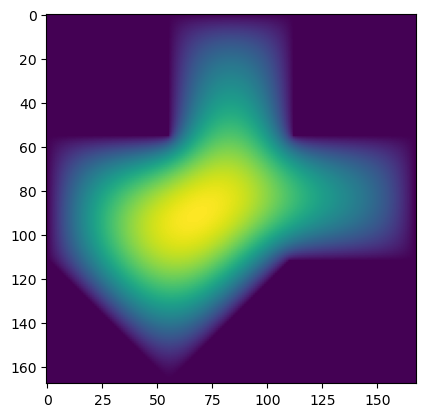

In [32]:
i=-1
plt.imshow(data[i].reshape((tocke[i],tocke[i])))
C(data[i].reshape((tocke[i],tocke[i])),1/tocke[i])

In [327]:
C_list=np.array(C_list)
ok_val = C_list[C_list < 0.59]
avg_C = np.average(ok_val[-5:])

Text(0, 0.5, '$C$')

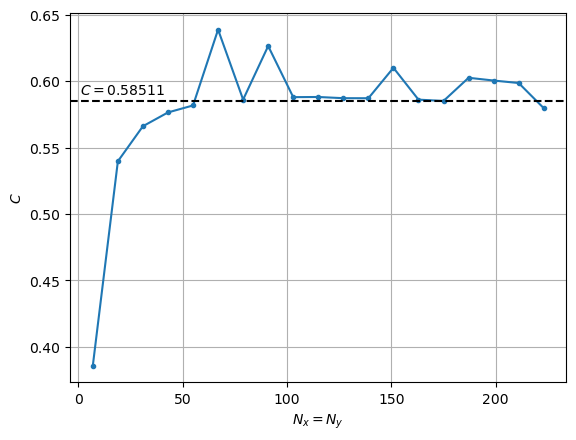

In [328]:
plt.plot(tocke, C_list, '.-')
# plt.plot(tocke, C_ref, '.-')
plt.grid()
plt.axhline(avg_C, c='k',ls='--')
plt.text(1,avg_C+0.005,f'$C={avg_C:.5f}$')
plt.xlabel('$N_x=N_y$')
plt.ylabel('$C$')
# plt.savefig('./slike/C_cev.pdf')

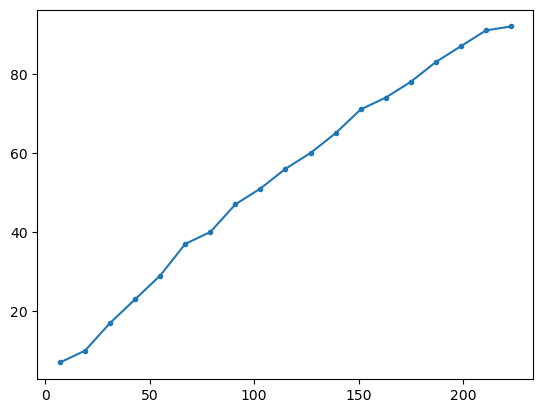

In [329]:
plt.plot(tocke, N_it, '.-')

## optimalen alpha

In [ ]:
sol=[]
def opt(alpha,N,Nx):
    omega = 2/(1+alpha*np.pi/Nx) #Nx=Ny
    v_sor = SOR(A,b, omega, RP1, N, Nx)
    res_sor = np.sum(np.abs(v_sor-v_lu))
    sol.append(alpha)
    return res_sor

In [ ]:
opt(1.6, N,Nx)

1.9748672137176625e-06

In [ ]:
sc.optimize.minimize_scalar(opt, args=(N,Nx),method='golden')

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.4901161193847656e-08 )
 success: True
     fun: 2.4896760484585333e-08
       x: 1.4957028406555084
     nit: 38
    nfev: 43

In [ ]:
sc.optimize.minimize_scalar(opt, args=(N,Nx),method='brent') #default

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: 1.0339647222253873e-07
       x: 1.4092574836472704
     nit: 27
    nfev: 30

In [ ]:
sol=[]
res = sc.optimize.minimize_scalar(opt, bracket=(1.5,1.7), args=(N,Nx))
res

 message: 
          Optimization terminated successfully;
          The returned value satisfies the termination criteria
          (using xtol = 1.48e-08 )
 success: True
     fun: 2.4896764308891656e-08
       x: 1.4957023121156214
     nit: 23
    nfev: 26

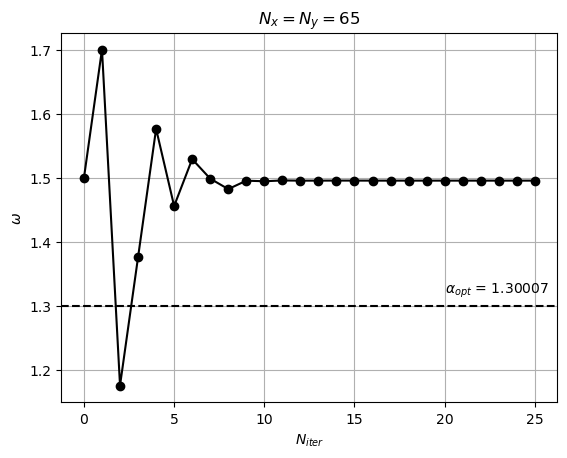

In [ ]:
omega_opt = res.x
plt.plot(sol,'ko-')
plt.axhline(omega_opt, c='k',ls='--')
plt.text(20, 0.02+omega_opt, f'$\\omega{{opt}}$ = {omega_opt:.5f}')
plt.grid()
plt.xlabel('$N_{iter}$')
plt.ylabel('$\omega$')
plt.title(f'$N_x=N_y=${Nx}')
# plt.savefig('./slike/opt_alpha_cev.pdf')

In [ ]:
def opt(alpha,N,A,b,Nx):
    omega = 2/(1+alpha*np.pi/Nx) #Nx=Ny
    v_sor = SOR(A,b, omega, RP1, N, Nx)
    v_lu = np.linalg.solve(A,b)
    res_sor = np.sum(np.abs(v_sor-v_lu))
    return res_sor

In [ ]:
def iter(scale,N_iter):
    dp = 1 #tlačni graident v z smeri
    Nx=Ny=1 + 3*scale #št. točk = št. delitev +1! večkratniki št. 3, zaradi delitve na tretjine
    dx=1./(Nx-1)
    dy=1./(Ny-1)
            
    # DE, RP
    A = np.zeros(((Nx)*(Ny), (Nx)*(Ny)))
    b = np.zeros(((Nx)*Ny))

    # DE
    for j in range(1,Ny-1):
        for i in range(1,Nx-1):
            if i*dx > L/3 and i*dx < 2*L/3 and j<2*Ny/3-1:
                # plt.plot(i*dx,j*dy,'ro')
                ij_index = j*(Nx) + i
                #print(i,j, ij_index)
                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            elif j*dy > H/3 and j*dy < 2*H/3:
                # plt.plot(i*dx,j*dy,'ro')
                ij_index = j*(Nx) + i
                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            elif j*dy >= 2*H/3 and i*dx<2*L/3 and ((i+2*Ny/3-2 >= j and i<=Nx/3) or (-i+4*Nx/3-2 > j and i>Nx/3)):
                # plt.plot(i*dx,j*dy,'bo')
                ij_index = j*(Nx) + i

                ij = 2*(1/dx**2 + 1/dy**2)
                ij_dx = -1/dx**2
                ij_dy = -1/dy**2
                #center
                A[ij_index, ij_index] += ij
                # okolica
                A[ij_index, ij_index-1] += ij_dx #levo
                A[ij_index, ij_index+1] += ij_dx #desno
                A[ij_index, ij_index-Nx] += ij_dy #dol
                A[ij_index, ij_index+Nx] += ij_dy #gor
                b[ij_index] = dp #tlačni gradient, viskoznost=1
            else: #izpust
                # plt.plot(i*dx,j*dy,'ko')
                ij_index = j*(Nx) + i
                #print(ij_index)
                A[ij_index, ij_index] = 1
                b[ij_index] = 0 #tlačni gradient, viskoznost=1
    #RP
    A,b = RP1(A,b,Nx)
    
    return sc.optimize.minimize_scalar(opt, args=(N_iter,A,b,Nx))

In [ ]:
N_iter = 100 #mora biti dovolj veliko!!
alpha_opt = []
tol=[]
scale_list = np.arange(1,31,1, dtype=int)
i=0
for scale in scale_list:
    i+=1
    print(f'{i}/{len(scale_list)}: {scale}')
    res = iter(scale, N_iter)
    alpha_opt.append(res.x)
    tol.append(res.fun)

1/30: 1
2/30: 2
3/30: 3
4/30: 4
5/30: 5
6/30: 6
7/30: 7
8/30: 8
9/30: 9
10/30: 10
11/30: 11
12/30: 12
13/30: 13
14/30: 14
15/30: 15
16/30: 16
17/30: 17
18/30: 18
19/30: 19
20/30: 20
21/30: 21
22/30: 22
23/30: 23
24/30: 24
25/30: 25
26/30: 26
27/30: 27
28/30: 28
29/30: 29
30/30: 30


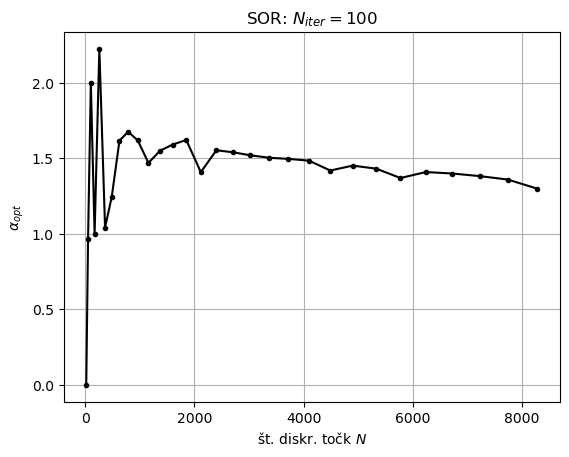

In [ ]:
N_point = (1+3*np.array(scale_list))**2
plt.plot(N_point, alpha_opt,'k.-')
plt.grid()
plt.xlabel('št. diskr. točk $N$')
plt.ylabel('$\\alpha_{opt}$')
plt.title(f'SOR: $N_{{iter}}=${N_iter}')
# plt.savefig('./slike/alpha_opt.pdf')

In [ ]:
tol

[0.0,
 1.062806564900904e-16,
 6.335645270928722e-15,
 2.661124153007767e-14,
 7.262500854870031e-14,
 1.8282219682963432e-13,
 4.119159278321517e-13,
 7.505641435804091e-13,
 9.804937148225066e-13,
 7.833433710181812e-13,
 1.9112127078353862e-11,
 4.28216260731516e-11,
 2.3124277225106234e-10,
 1.0794073659821953e-09,
 1.0339647222253873e-07,
 4.25621291970842e-08,
 2.971585702121148e-07,
 1.3159112381561203e-06,
 3.340356021881598e-06,
 8.546538487933408e-06,
 2.773103068858617e-05,
 0.0001089094772271965,
 0.00014155163433144353,
 0.0002843731611731614,
 0.000850435953828893,
 0.0011528742509210152,
 0.002010218352389248,
 0.0034570475760145793,
 0.005837554638993384,
 0.012329357114365625]